In [2]:
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/impport_packages.ipynb"    #import all necessary packages - numpy, pandas etc
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/simulation_class.ipynb"    #import all necessary packages - numpy, pandas etc
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/create_world.ipynb"

### Reformulation

- Define the **maternal deviation**:


##### $\delta_t$= Phenotype of the mother - Genetic contribution of mother
##### $\delta_t$ = $P_{t-1} - G_{t-1}$

so that the phenotype is the sum of the genetic component of the current generation and maternal deviation from its phenotype:

$$
P = G_t + \omega * \delta_t + \varepsilon_{d}
$$

- We also separate mutation-related noise $\varepsilon_{m}$ from parental phenotype inheritance noise $\varepsilon_{epi}$.  
- We define a evolvable 'weight' term $\omega$: determines how much importance to give each term of the equation
- We also add developmental noise: purely environmental noise in teh form of  $\varepsilon_{d}$


The full new formulation becomes:

$$
Z' = (G_t + \varepsilon_{m}) + (\omega + \varepsilon_{epi})*(\delta_t) +  \varepsilon_{d}
$$

---

In [67]:
def create_world(rho_cases, m_cases, max_gen):
    

    # Define rho and m grid
    rho = np.linspace(0.75, 0.99, rho_cases)
    m = np.linspace(0.50, 0.75, m_cases)

    RHO, M = np.meshgrid(rho, m)

    # Define ALPHA and BETA
    ALPHA = (1 - RHO) * (1 - M)
    BETA = (1 - RHO) * M

    # Flatten and create DataFrame
    data_env = np.column_stack((RHO.flatten(),
                                M.flatten(),
                                ALPHA.flatten(),
                                BETA.flatten()))

    n_scenarios= len(RHO.flatten())
    n_gen = max_gen

    opt = np.array([0, 1])
    Env = np.zeros((n_scenarios, n_gen), dtype=int) #same as hannas E()

    p = np.random.uniform(low=0, high=1, size=(n_scenarios, n_gen))
    alpha = ALPHA.flatten()
    beta =  ALPHA.flatten()

    for g in range(0, (n_gen-1)):
        
        Env[:, g+1] = Env[:, g]
        
        # Transitions
        cAB = (Env[:, g] == 0) & (p[:,g] < alpha)  #use boolean operator & to ask; which rows have a0 and
        cBA = (Env[:, g] == 1) & (p[:,g] < beta)

        Env[cAB, g+1] = 1  # A→B transitions
        Env[cBA, g+1] = 0  # B→A transitions
        
    env_values = opt[Env]  # final result
    
    full_data_env_env_values = np.concatenate((data_env,env_values),axis=1) # attach rho and mvales to full list of environmental values
    
    # Mask where ALPHA > 1 or BETA > 1
    mask = (full_data_env_env_values[:, 2] > 1) | (full_data_env_env_values[:, 3] > 1)

    # Set ALPHA and BETA (columns 2 and 3) to NaN where mask is True
    full_data_env_env_values[mask, 2:] = np.nan


    # Equilibrium stats
    return full_data_env_env_values
        

In [68]:
def create_cube(popsize, dims, nof_dimensions, epsilon=0.1, initial_memory=-3):
    
    """
    Create and initialize a population cube N with genotype, phenotype,
    and developmental layers.

    Parameters:
        popsize (int): Number of individuals in the population.
        dims (dict): Output from get_cube_dims().
        nof_dimensions (int): Number of dimensions (traits).
        epsilon (float): Random noise factor for phenotype initialization.

    Returns:
        np.ndarray: Initialized cube with dimensions [popsize, total_layers].
    """
    
    # Initialize cube
    N = np.empty((popsize, dims['total_layers']))
    
    # Initialize memory & neutral layers
    N[:, dims['memory']:dims['neutral'] + 1] = initial_memory

    # Initialize genotype layer
    N[:, dims['geno']] = np.ones((popsize, nof_dimensions))  #the phenotype is initialized at 1 to be adapted to the '1' environemnt, so opposite

    # Initialize phenotype layer with mut
    N[:, dims['pheno']] = N[:, dims['geno']] + epsilon * np.random.randn(popsize, nof_dimensions)

    # Initialize development layer with NaN
    N[:, dims['dev']] = np.nan

    return N

In [69]:
def run_simulation(params):
    scenarios, popsize, maxgen, dims, N, mutsize, mutrate, epsilon, nof_dimensions, only_genetics = params
    
    rho_m_alpha_beta = scenarios[0:4]
    env_states = scenarios[4:]
  
    

    meanw = np.zeros(maxgen)
    meanmemory_g = np.zeros(maxgen)
    meanmemory_p= np.zeros(maxgen)
    meanneutral_g = np.zeros(maxgen)
    meanneutral_p = np.zeros(maxgen)
    mean_gen = np.zeros(maxgen)
    mean_pheno = np.zeros((nof_dimensions, maxgen))
    
    for t in range(0, (maxgen-1)):
        #if t%10 == 0:
        #    print(t)
        for d in range(0, nof_dimensions):
            N[:,dims['dev'][d]] = N[:,dims['pheno'][d]] - env_states[t]
            
        dist_from_optima = np.sqrt(np.sum(N[:,dims['dev']]**2, axis =1))
        
        #------distance correction ------
        def between_optima_dist(dims):
            multi_d_diff = np.ones(dims) - np.zeros(dims)
            
            return np.sqrt(np.sum(multi_d_diff**2))
        #-----------------------------
        normalised_dist = dist_from_optima/between_optima_dist(nof_dimensions) 
        
        W = np.exp((-normalised_dist**2)/ (2))
        
        
        meanw[t] = np.mean(W)    
    
        
        meanmemory_g[t] = np.mean(N[:, dims['memory']])  # the actual memory
        meanmemory_p[t] = np.mean(1/(1 + np.exp(-N[:,dims['memory']]))) #with the logistc correction
        
        meanneutral_g[t] = np.mean(N[:,dims['neutral']])
        meanneutral_p[t] = np.mean(1/(1 + np.exp(-N[:,dims['neutral']])))
        mean_gen[t] = np.mean(N[:,dims['geno']])
        
        mean_pheno[:, t] = [np.mean(N[:, dims['pheno'][i]]) for i in range(nof_dimensions)]

        
        #current gen offspring (the cube gets stored here per gen)
        
        offspring = np.zeros((popsize, dims['total_layers'])) # empty 3D matrix with dimensions of the cube
        
        #sample offspring for each scenario weighted by fitness
        
        
        parents_idx = np.random.choice(popsize, size=popsize, p = (W/np.sum(W)) )#pick #popsize sized random numbers
        offspring[:,:] = N[parents_idx, :] #similar to how it works in matlab
        
        mutate_memories = np.random.uniform(low=0, high=1, size= popsize) < mutrate[0]
        #mutate_neutral = np.random.uniform(low=0, high=1, size=popsize) < mutrate[0]
        mutate_geno = np.random.uniform(low=0, high=1, size=(popsize, nof_dimensions)) < mutrate[1]
        
        # adding a mutation of size mutsize[1], rate mutate_memories, to the epi-memory
        # the epignetic memory evolves; 
        
        offspring[:,dims['memory']] = (
                                offspring[:,dims['memory']] 
                                + mutate_memories * np.random.normal(0, mutsize[0], popsize)
        )
        
        # adding a mutation of size mutsize[1] (epi-mutation size), rate mutate_memories, to the neutral phenotype
        # the neutral trait recieves random mutation but is not implemented in the calculation for fitness; so is evolving neutrally
        offspring[:,dims['neutral']] = (
                                offspring[:,dims['neutral']]  
                                + mutate_memories * np.random.normal(0, mutsize[0], popsize)
        ) 
        
        # adding a mutation of size mutsize[2] (genetic mutation size), rate mutate_memories, to the genotype

        offspring[:,dims['geno']] = (
                            offspring[:,dims['geno']] 
                            + mutate_geno * np.random.normal(0, mutsize[1], size=(popsize, nof_dimensions) )
        )
        
        
        # Construct the phenotype
        if only_genetics :
            if t % 10000 == 0:
                print(f"Gen {t}: Running ONLY genetics mode")
            
            for i in range(0, nof_dimensions):
                offspring[:, dims['pheno'][i]] = (
                offspring[:, dims['geno'][i]]
                + np.random.normal(0, epsilon, size=popsize) )
        else:
            if t % 10000 == 0:
                print(f"Gen {t}: Running EPIGENETIC mode")
            
            for i in range(0, nof_dimensions):
                    offspring[:, dims['pheno'][i]] = (
                        offspring[:, dims['geno'][i]] #genotype
                        + np.random.normal(0, epsilon, size=popsize) # adding random noise (developemental noise, nromally distributed with epsilon variance)
                        + ((1 / (1 + np.exp(-offspring[:, dims['memory']]))) #phenotype version of the memory (y axis) 
                        * (N[parents_idx, dims['pheno'][i]] - N[parents_idx, dims['geno'][i]]))# adding the deviation -> read as weight (phenotypic component * deviation)
                    )
        N = offspring
        
        
    return {
        'rho_m_alpha_beta' :rho_m_alpha_beta, ## Make sure this is indented!!
        'maxgen_popsize': [maxgen,popsize],
        'meanw': meanw,
        'meanmemory_p': meanmemory_p,
        'meanneutral_p': meanneutral_p,
        'mean_pheno': mean_pheno  # (nof_dimensions, maxgen)
        }
        


In [70]:
maxgen = 10000
full_env_values = create_world(10, 10, maxgen)   # create world (input: generations, no. rhos and no. ms) 
print(full_env_values.shape)

clean_data_env = full_env_values[~np.isnan(full_env_values).any(axis=1)]
clean_data_env

(100, 10004)


array([[0.75      , 0.5       , 0.125     , ..., 0.        , 0.        ,
        0.        ],
       [0.77666667, 0.5       , 0.11166667, ..., 0.        , 0.        ,
        0.        ],
       [0.80333333, 0.5       , 0.09833333, ..., 1.        , 1.        ,
        1.        ],
       ...,
       [0.93666667, 0.75      , 0.01583333, ..., 0.        , 0.        ,
        0.        ],
       [0.96333333, 0.75      , 0.00916667, ..., 0.        , 0.        ,
        0.        ],
       [0.99      , 0.75      , 0.0025    , ..., 0.        , 0.        ,
        0.        ]], shape=(100, 10004))

In [64]:

nof_scenarios = np.shape(clean_data_env)[0]
print('nof_scenarios:', nof_scenarios) 

rho_m_alpha_beta = clean_data_env[0:4]
env_states = clean_data_env[4:]


nof_scenarios: 100


In [71]:
popsize = 5000

# Mutation rates: [epi-memory mutation rate, geno mutation rate]
mutrate = [0.0001, 0.0001]

# Mutation sizes: [epi-memory mutation size, geno mutation size]
mutsize = [1, 1]

epsilon = 0.05 # phenotypic noise
                                 
initial_memory = 0

results_array = {}  ### DONT FORGET TO RUN BEFORE NEW PARAM CONDITIONS

mutrate[0]*mutsize[0]

maxgen = 10000

 mutrate = [0.0001, 0.0001] seems to produce mutation sizes that are good enouhgh for for attaining high values and not fluctuating a lot because of too much highness

In [72]:
onlygen = False

# Number of dimensions (can be 1 or more)
nof_dimensions = 1

# get the cube dimensions
dims = get_cube_dims(nof_dimensions)

#create the cube
N = create_cube(popsize, dims=dims, nof_dimensions=nof_dimensions, epsilon=epsilon, initial_memory=initial_memory)

print(N.shape)


(5000, 5)


In [73]:
if __name__ == '__main__':
    
    # Create all combinations of sigma_mut and sigma_alpha
    param_grid = [
        (scenario, popsize, maxgen, dims, N, mutsize, mutrate, epsilon, nof_dimensions, True) #only genetics can either be True or false
        for _, scenario in enumerate(clean_data_env) #where each row corresponds to one scenario
    ]

    num_cpus = 10
    
    with concurrent.futures.ProcessPoolExecutor(num_cpus) as executor: 
        results_array_epi = list(executor.map(run_simulation, param_grid))
        #results_array_gen = list(executor.map(run_simulation, param_grid))


Gen 0: Running ONLY genetics modeGen 0: Running ONLY genetics modeGen 0: Running ONLY genetics mode

Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics modeGen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics modeGen 0: Running ONLY genetics modeGen 0: Running ONLY genetics mode


Gen 0: Running ONLY genetics mode


Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running ONLY genetics mode
Gen 0: Running

In [74]:
#Collect keys of all the list objects 
keys = list(results_array_epi[0].keys())

concatenated_results_epi = {}
concatenated_results_gen = {}

for k in keys:
        concatenated_results_epi[k] = np.vstack([r[k] for r in results_array_epi])
        concatenated_results_gen[k] = np.vstack([r[k] for r in results_array_gen])

In [60]:
keys


['rho_m_alpha_beta',
 'maxgen_popsize',
 'meanw',
 'meanmemory_p',
 'meanneutral_p',
 'mean_pheno']

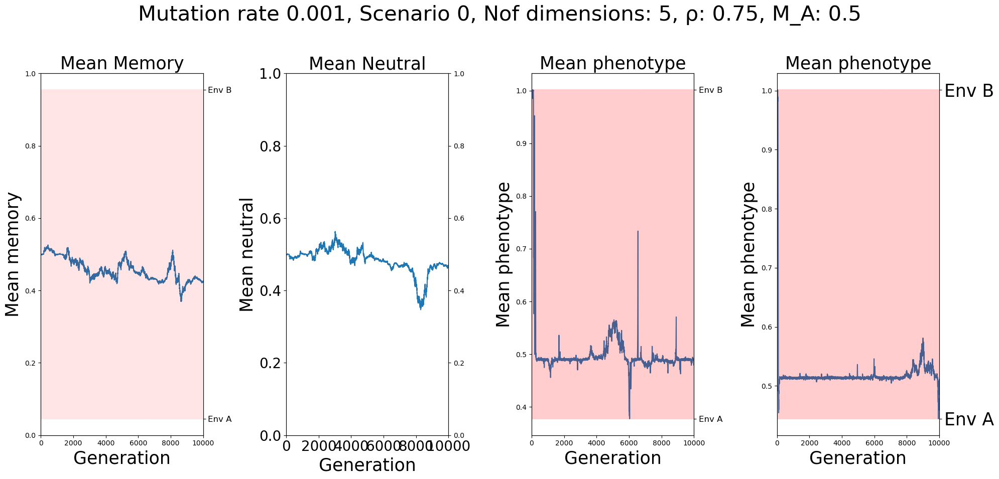

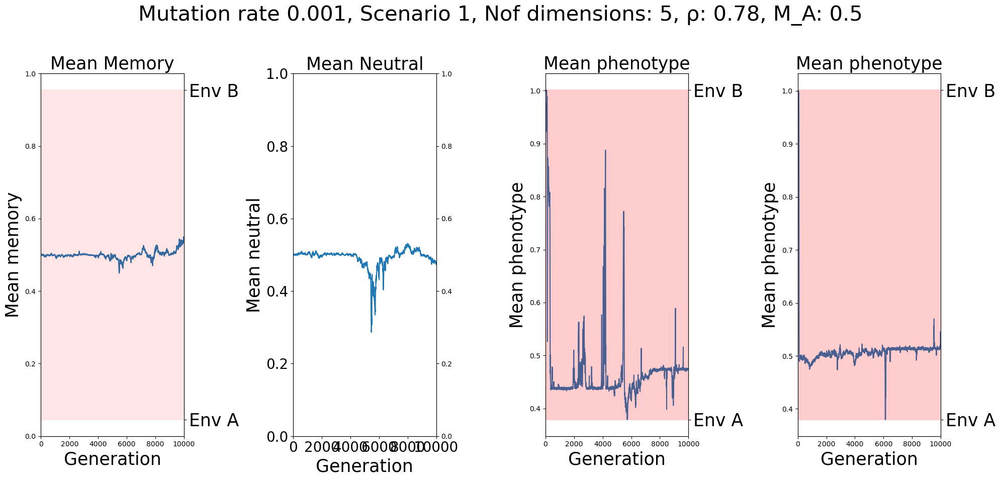

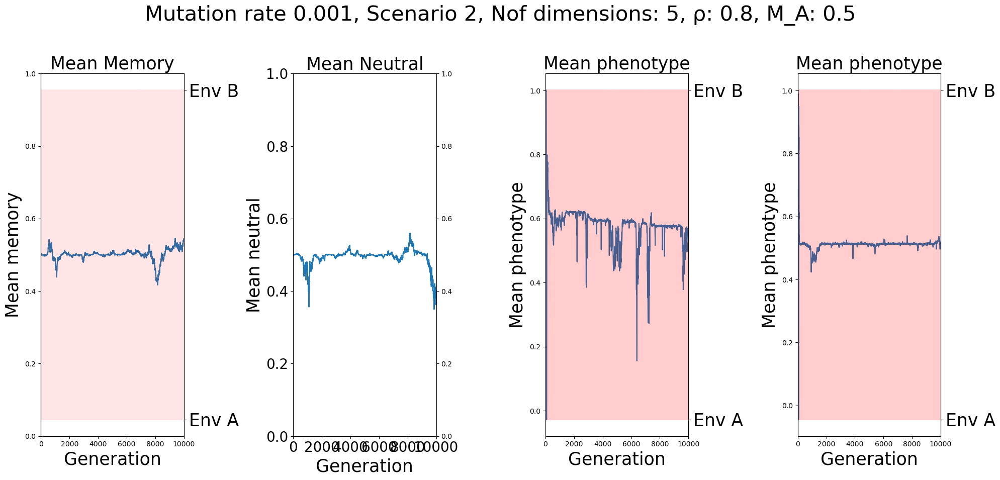

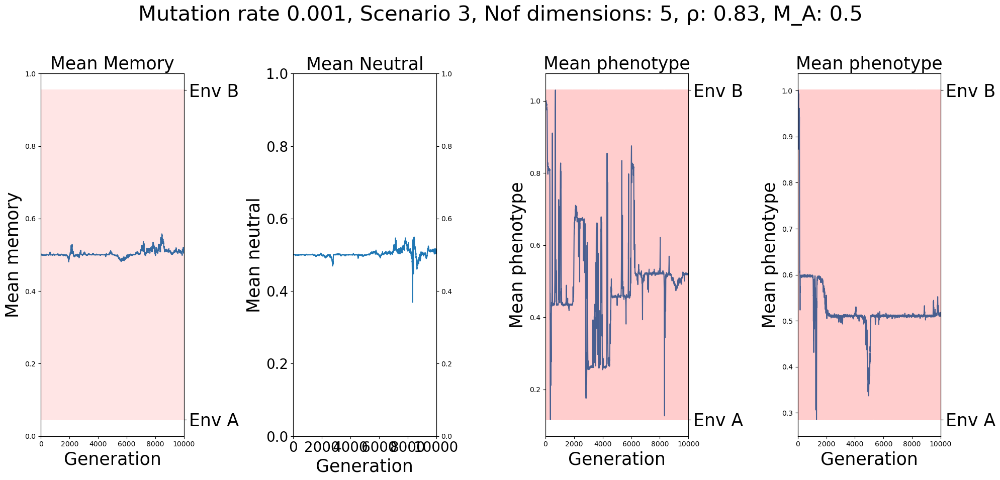

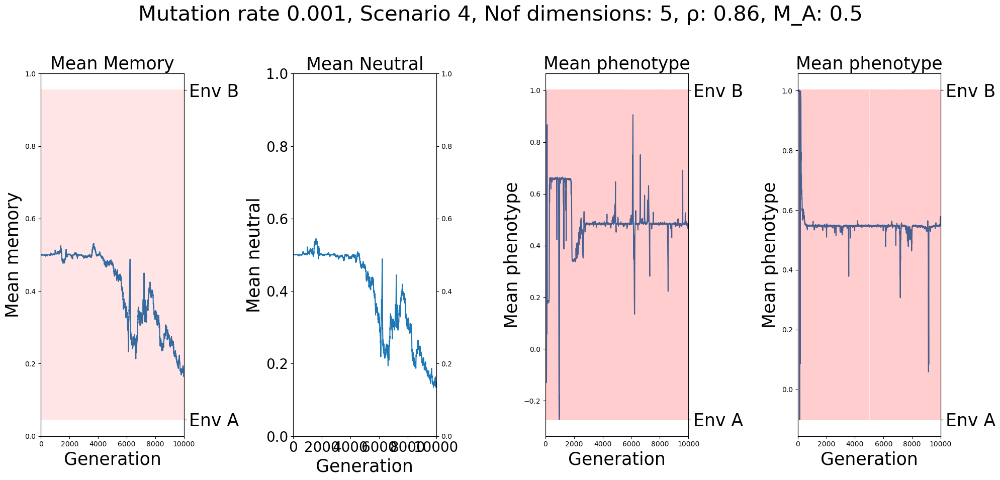

...

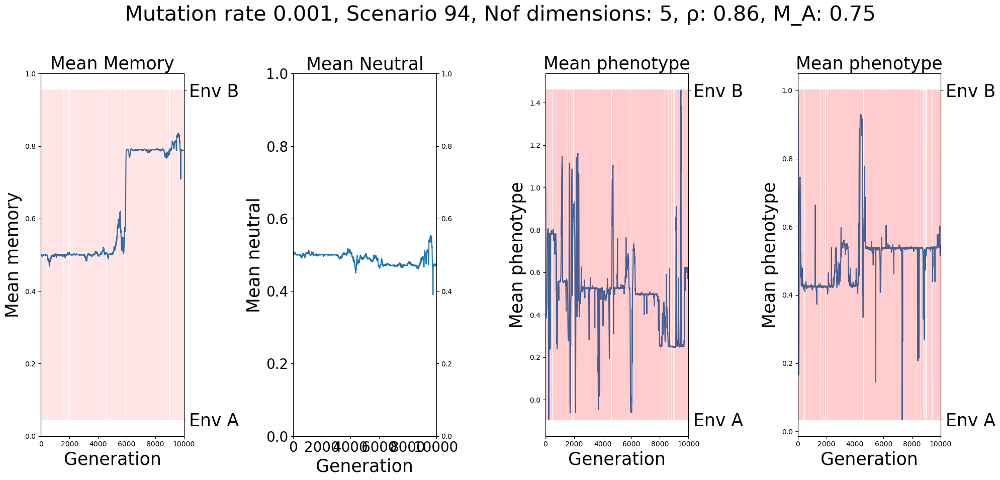

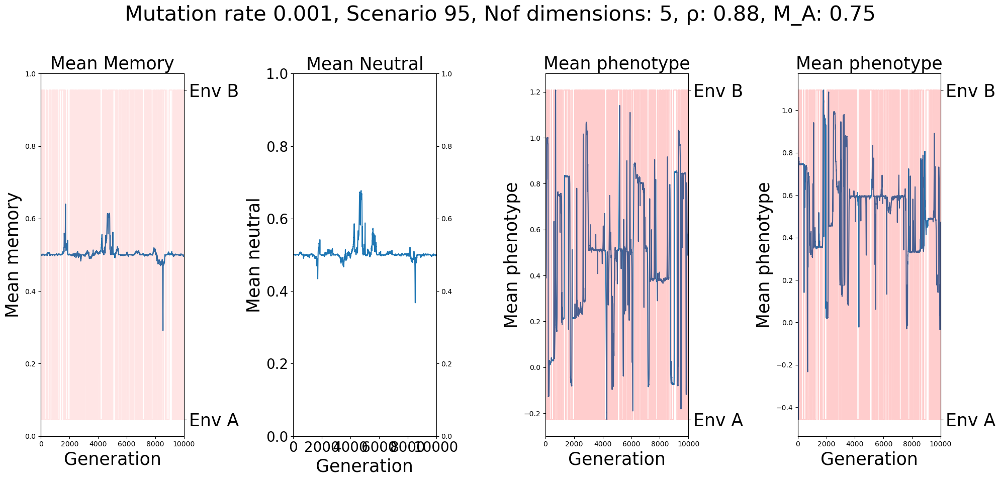

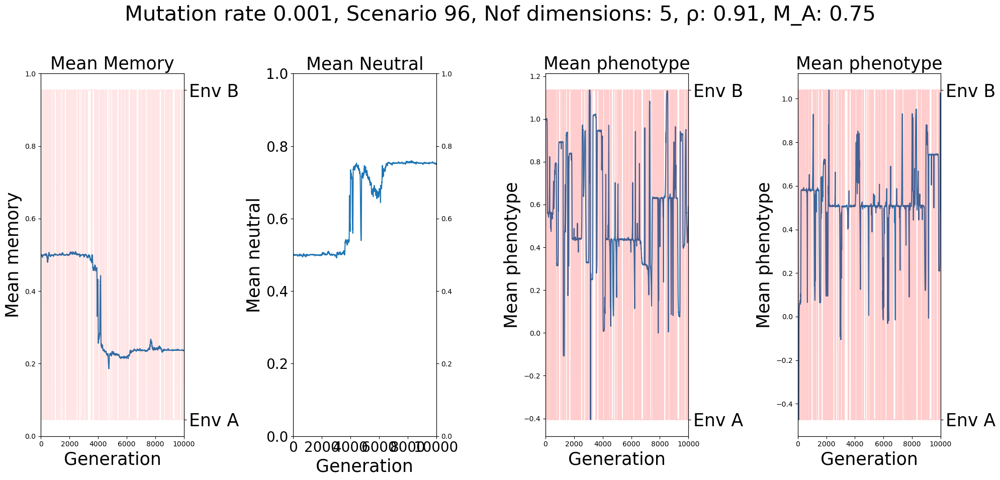

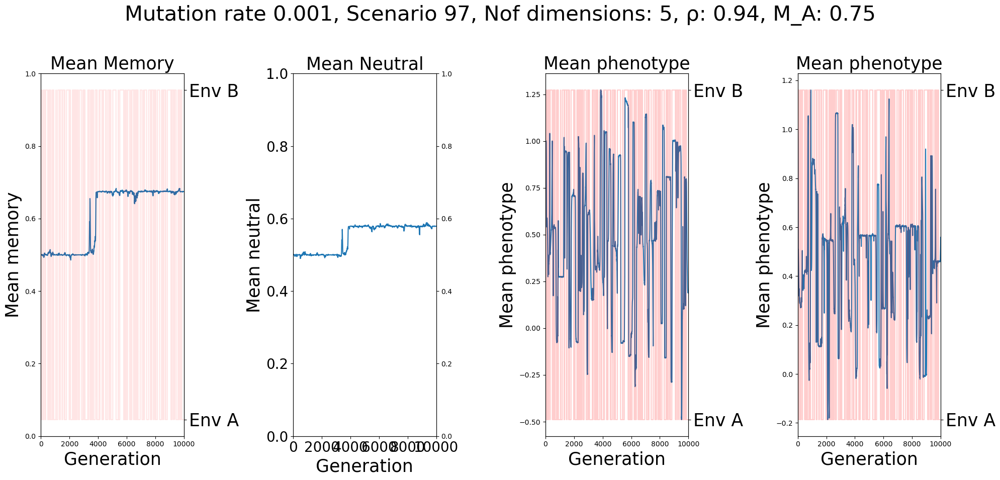

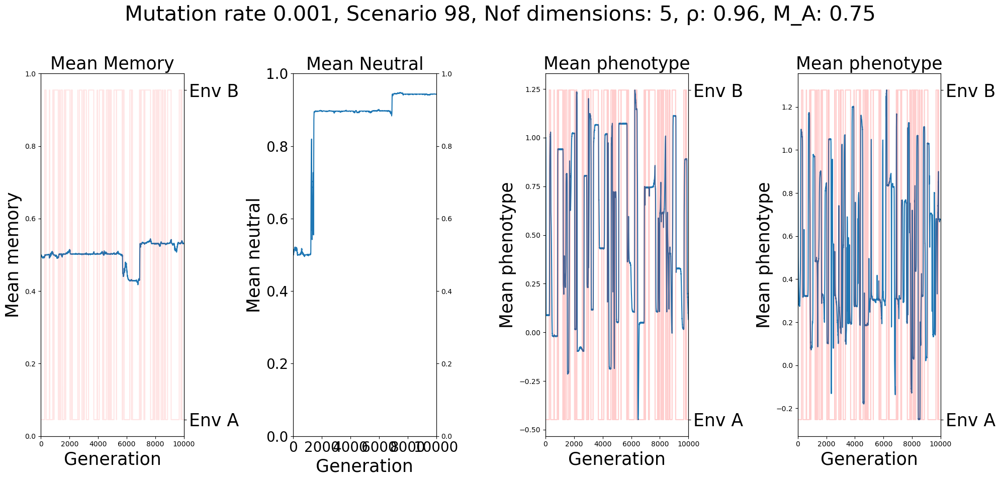

In [75]:
nof_scenarios = np.shape(clean_data_env)[0]
nof_dims=5
start = 0
stop = 99
text_size=12

for i in range(start, stop):
    
    clean_data_env_optima =  clean_data_env[i, 4:-1]
    clean_data_env_env_params = clean_data_env[i, 0:4]
    meanmemory_p = concatenated_results_epi['meanmemory_p'][i, :-1]
    meanneutral_p = concatenated_results_epi['meanneutral_p'][i, :-1]
    mean_phenotype = concatenated_results_epi['mean_pheno'][i, :-1]
    mean_phenotype_gen = concatenated_results_gen['mean_pheno'][i, :-1]
    
    concatenated_results = {}

    # Extract variables

    maxgen = meanmemory_p.shape[0]
    gens = np.arange(1, maxgen +1 )   #Proper x-axis

    # Create figure once (outside loop)
    fig, ax = plt.subplots(1, 4, figsize=(20, 10), sharex=True)
    ax2 = ax[0].twinx()


    # Left plot: mean memory
    ax[0].plot(gens, meanmemory_p)
  
    ax2.plot(gens, clean_data_env_optima, color='red',  alpha = 0.1)
    ax2.set_yticks([0, 1], ["Env A","Env B"], fontsize =text_size)
    ax2 = ax[1].twinx()

    # Right plot: mean neutral
    ax[1].plot(meanneutral_p)
  
    ax2 = ax[2].twinx()
    ax2.plot(gens, clean_data_env_optima, color='red', alpha = 0.1)
    ax2.set_yticks([0, 1], ["Env A","Env B"], fontsize =text_size)
    
    # Add labels, limits, and legends once
    text_size = 25
    axis_size= 20
    
    ax[0].set_title("Mean Memory", fontsize =text_size)
    ax[0].set_ylabel("Mean memory", fontsize =text_size)
    ax[0].set_xlabel("Generation", fontsize =text_size)
    ax[0].set_xlim(1, maxgen)
    ax[0].set_ylim(0, 1)

    ax[1].set_title("Mean Neutral", fontsize =text_size)
    ax[1].set_ylabel("Mean neutral", fontsize =text_size)
        
    ax[1].set_xlabel("Generation", fontsize =text_size)
    ax[1].set_xlim(1, maxgen)
    ax[1].set_ylim(0, 1)
    ax[1].tick_params(axis='both', labelsize=axis_size)
    ax[1].tick_params(axis='both', labelsize=axis_size)
    
    ax[2].plot(mean_phenotype)
    ax[2].set_title("Mean phenotype", fontsize =text_size)
    ax[2].set_ylabel("Mean phenotype", fontsize =text_size)
    ax[2].set_xlabel("Generation", fontsize =text_size)
    ax[2].set_xlim(1, maxgen)
    ax[2].set_xlim(0, 10000)
    ax2.plot(gens, clean_data_env_optima, color='red', alpha = 0.1)
     
    ax2_gen = ax[3].twinx()
    ax2_gen.plot(gens, clean_data_env_optima, color='red', alpha = 0.1)
    ax2_gen.set_yticks([0, 1], ["Env A","Env B"], fontsize =text_size)

    ax[3].plot(mean_phenotype_gen)
    ax[3].set_title("Mean phenotype", fontsize =text_size)
    ax[3].set_ylabel("Mean phenotype", fontsize =text_size)
    ax[3].set_xlabel("Generation", fontsize =text_size)
    ax[3].set_xlim(1, maxgen)
    ax[3].set_xlim(0, 10000)
    ax2_gen.plot(gens, clean_data_env_optima, color='red', alpha = 0.1)
    
    fig.suptitle(f"Mutation rate 0.001, Scenario {i}, Nof dimensions: {nof_dims}, ρ: {round(clean_data_env_env_params[0],2)}, M_A: {round(clean_data_env_env_params[1],2)}", fontsize=30)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()